In [40]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../postprocessing").resolve()))
from conversion_gpx import convert_gpx_to_csv

### Chargement des données

In [41]:
gpx_file = Path("Acquisition_4_48.gpx")
csv_gpx_output = Path("Acquisition_4_48.csv")

In [49]:
# conversion gpx vers cv
convert_gpx_to_csv(gpx_file, csv_gpx_output)

Conversion terminée ! Fichier enregistré : Acquisition_4_48.csv


In [50]:
donnees_imu_gnss = pd.read_csv("synced_imu_gnss.csv")

#donnees_strava = pd.read_csv(csv_gpx_output) #utiliser si besoin d'utiliser gpx convertit en csv
donnees_strava = pd.read_csv("strava_temp.csv")

print("Données IMU/GNSS chargées :", donnees_imu_gnss.shape)
print("Données Strava chargées :", donnees_strava.shape)

Données IMU/GNSS chargées : (716, 15)
Données Strava chargées : (730, 3)


### Aperçu des données

In [44]:
print("\n Les données IMU/GNSS ")
print(donnees_imu_gnss.head())


 Les données IMU/GNSS 
      timestamp   accel_x   accel_y   accel_z     gyro_x     gyro_y  \
0  1.779458e+09  0.961055 -0.032452  0.164151   1.638336   4.456608   
1  1.779458e+09  0.907558 -0.054595  0.152439  19.672086 -16.342142   
2  1.779458e+09  0.978074 -0.067344  0.073444   3.843336   8.481608   
3  1.779458e+09  0.951661 -0.060512  0.157319  15.244586 -11.459642   
4  1.779458e+09  0.992104  0.036356  0.083143  -2.281664   1.805358   

      gyro_z     mag_x     mag_y     mag_z   latitude  longitude  hdop  pdop  \
0   0.875428 -0.659749  0.519731 -0.094709  49.385475   1.067640   0.8   1.4   
1  11.970428 -0.659749  0.519731 -0.094709  49.385475   1.067635   0.8   1.4   
2   7.402928 -0.659749  0.519731 -0.094709  49.385475   1.067632   0.8   1.4   
3 -13.850822 -0.659749  0.519731 -0.094709  49.385475   1.067628   0.8   1.3   
4  -4.295822 -0.659749  0.519731 -0.094709  49.385476   1.067623   0.8   1.3   

   vdop  
0   1.1  
1   1.1  
2   1.1  
3   1.1  
4   1.1  


In [45]:
print("\n Les données Strava ")
print(donnees_strava.head())


 Les données Strava 
                     UTC   Latitude  Longitude
0  2026/05/22 - 13:54:15  49.385485   1.067516
1  2026/05/22 - 13:54:16  49.385485   1.067516
2  2026/05/22 - 13:54:25  49.385477   1.067600
3  2026/05/22 - 13:54:26  49.385478   1.067606
4  2026/05/22 - 13:54:27  49.385473   1.067618


### Nettoyage

In [46]:
imu = donnees_imu_gnss.copy()
strava = donnees_strava.copy()

imu = imu.rename(columns={
    "latitude": "Latitude",
    "longitude": "Longitude"
})

# On enlève les coordonnées impossibles
imu = imu[
    imu["Latitude"].between(-90, 90) &
    imu["Longitude"].between(-180, 180)
].copy()

# On garde les points IMU proches de la trajectoire Strava en definissant une marge
marge = 0.001

lat_min = strava["Latitude"].min() - marge
lat_max = strava["Latitude"].max() + marge
lon_min = strava["Longitude"].min() - marge
lon_max = strava["Longitude"].max() + marge

imu = imu[
    imu["Latitude"].between(lat_min, lat_max) &
    imu["Longitude"].between(lon_min, lon_max)
].copy()

print("Points IMU/GNSS gardés :", len(imu))
print("Points Strava gardés   :", len(strava))

Points IMU/GNSS gardés : 716
Points Strava gardés   : 730


### Comparaison des trajectoires

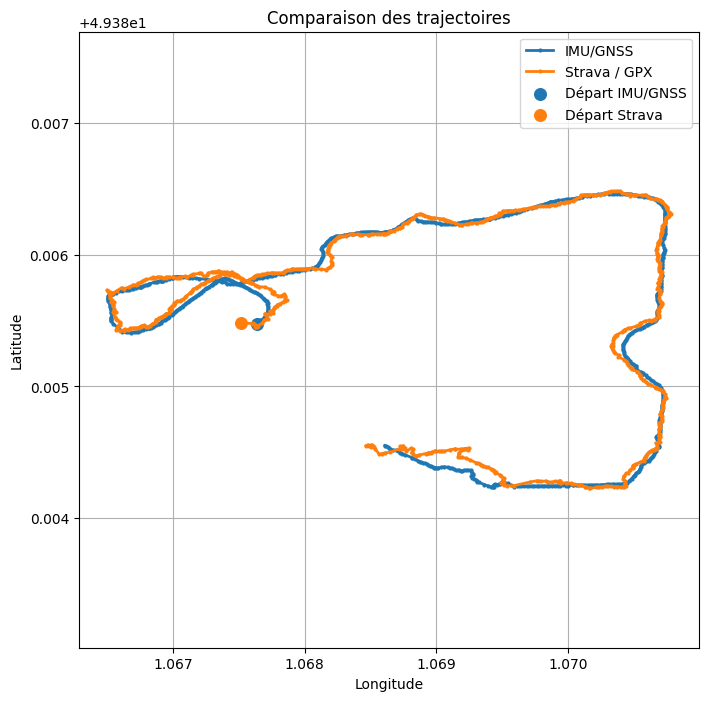

In [47]:
plt.figure(figsize=(8, 8))

plt.plot(
    imu["Longitude"],
    imu["Latitude"],
    label="IMU/GNSS",
    linewidth=2,
    marker="o",
    markersize=2
)

plt.plot(
    strava["Longitude"],
    strava["Latitude"],
    label="Strava / GPX",
    linewidth=2,
    marker="o",
    markersize=2
)

plt.scatter(imu["Longitude"].iloc[0], imu["Latitude"].iloc[0], s=70, label="Départ IMU/GNSS")
plt.scatter(strava["Longitude"].iloc[0], strava["Latitude"].iloc[0], s=70, label="Départ Strava")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Comparaison des trajectoires")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

### Ecart entre les trajectoires

In [48]:

imu["UTC"] = pd.to_datetime(
    imu["timestamp"], unit="s", utc=True
).astype("datetime64[ns, UTC]")

strava["UTC"] = pd.to_datetime(
    strava["UTC"], format="%Y/%m/%d - %H:%M:%S", utc=True
).astype("datetime64[ns, UTC]")

imu_cmp = imu[["UTC", "Latitude", "Longitude"]].sort_values("UTC").rename(columns={
    "Latitude": "Latitude_imu",
    "Longitude": "Longitude_imu"
})

strava_cmp = strava[["UTC", "Latitude", "Longitude"]].sort_values("UTC").rename(columns={
    "Latitude": "Latitude_strava",
    "Longitude": "Longitude_strava"
})

print(imu_cmp["UTC"].dtype)
print(strava_cmp["UTC"].dtype)

comparaison = pd.merge_asof(
    imu_cmp,
    strava_cmp,
    on="UTC",
    direction="nearest",
    tolerance=pd.Timedelta("1s")
).dropna()

R = 6371000

lat1 = np.radians(comparaison["Latitude_imu"])
lon1 = np.radians(comparaison["Longitude_imu"])
lat2 = np.radians(comparaison["Latitude_strava"])
lon2 = np.radians(comparaison["Longitude_strava"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
angle = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

comparaison["ecart_m"] = R * angle

print("Nombre de points comparés :", len(comparaison))
print(f"Ecart moyen  : {comparaison['ecart_m'].mean():.2f} m")
print(f"Ecart median : {comparaison['ecart_m'].median():.2f} m")
print(f"Ecart max    : {comparaison['ecart_m'].max():.2f} m")

comparaison.head()

datetime64[ns, UTC]
datetime64[ns, UTC]
Nombre de points comparés : 716
Ecart moyen  : 6.08 m
Ecart median : 4.64 m
Ecart max    : 22.10 m


,UTC,Latitude_imu,Longitude_imu,Latitude_strava,Longitude_strava,ecart_m
0,2026-05-22 13:54:24.452885151+00:00,49.385475,1.067640,49.385477,1.067600,2.864036
1,2026-05-22 13:54:25.642196417+00:00,49.385475,1.067635,49.385478,1.067606,2.122652
2,2026-05-22 13:54:26.446604490+00:00,49.385475,1.067632,49.385478,1.067606,1.911324
3,2026-05-22 13:54:27.667697191+00:00,49.385475,1.067628,49.385461,1.067643,1.957410
4,2026-05-22 13:54:28.531939983+00:00,49.385476,1.067623,49.385456,1.067635,2.404783


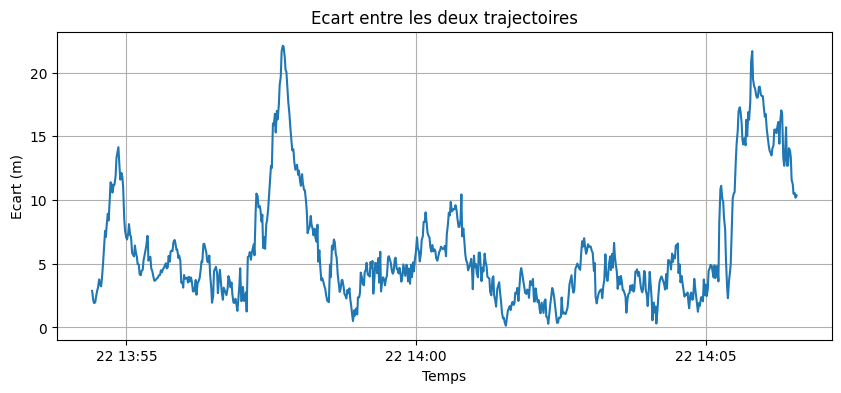

In [35]:

plt.figure(figsize=(10, 4))
plt.plot(comparaison["UTC"], comparaison["ecart_m"])
plt.xlabel("Temps")
plt.ylabel("Ecart (m)")
plt.title("Ecart entre les deux trajectoires")
plt.grid(True)
plt.show()

### # Histogramme des erreurs

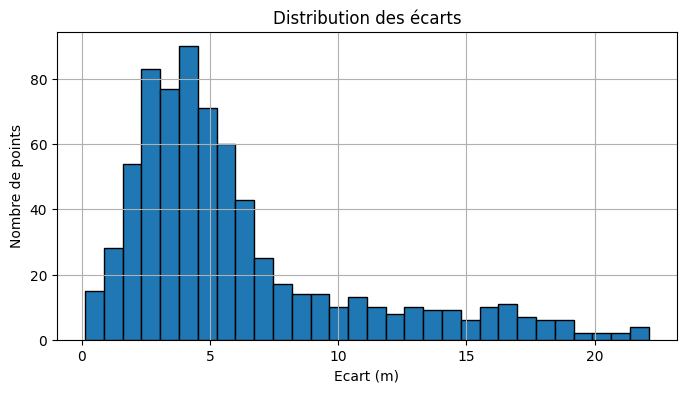

In [36]:
plt.figure(figsize=(8, 4))
plt.hist(comparaison["ecart_m"], bins=30, edgecolor="black")
plt.xlabel("Ecart (m)")
plt.ylabel("Nombre de points")
plt.title("Distribution des écarts")
plt.grid(True)
plt.show()

In [37]:
# Fonction pour calculer la distance totale parcourue
def distance_haversine(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    angle = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * angle

In [38]:
# Distance totale IMU/GNSS
dist_imu = distance_haversine(
    imu["Latitude"].values[:-1],
    imu["Longitude"].values[:-1],
    imu["Latitude"].values[1:],
    imu["Longitude"].values[1:]
).sum()

# Distance totale Strava
dist_strava = distance_haversine(
    strava["Latitude"].values[:-1],
    strava["Longitude"].values[:-1],
    strava["Latitude"].values[1:],
    strava["Longitude"].values[1:]
).sum()

print(f"Distance totale IMU/GNSS : {dist_imu:.2f} m")
print(f"Distance totale Strava   : {dist_strava:.2f} m")
print(f"Ecart sur distance totale: {abs(dist_imu - dist_strava):.2f} m")


Distance totale IMU/GNSS : 925.11 m
Distance totale Strava   : 1103.76 m
Ecart sur distance totale: 178.64 m
